In [ ]:
# 1. Verificar se a GPU está ativa
!nvidia-smi

# 2. Instalar a biblioteca Ultralytics (YOLOv8) e dependências para o COCO
!pip install ultralytics FiftyOne

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
import fiftyone as fo
import fiftyone.zoo as foz

# Baixar o subconjunto do COCO contendo as classes desejadas
dataset = foz.load_zoo_dataset(
    "coco-2017",
    split="validation", # Usando validation para um download rápido de exemplo
    label_types=["detections"],
    classes=["dog", "bicycle"],
    max_samples=100
)

# Exportar no formato aceito pela YOLO
export_dir = "./coco_custom"
label_field = "ground_truth"

dataset.export(
    export_dir=export_dir,
    dataset_type=fo.types.YOLOv5Dataset,
    label_field=label_field,
    classes=["dog", "bicycle"],
)
print("Download e exportação concluídos!")

/usr/local/lib/python3.13/dist-packages/glob2/fnmatch.py:141: SyntaxWarning: invalid escape sequence '\Z'
  return '(?ms)' + res + '\Z'


INFO:fiftyone.zoo.datasets:Downloading split 'validation' to '/root/fiftyone/coco-2017/validation' if necessary


INFO:fiftyone.utils.coco:Downloading annotations to '/root/fiftyone/coco-2017/tmp-download/annotations_trainval2017.zip'


 100% |██████|    1.9Gb/1.9Gb [5.1s elapsed, 0s remaining, 413.1Mb/s]       


INFO:eta.core.utils: 100% |██████|    1.9Gb/1.9Gb [5.1s elapsed, 0s remaining, 413.1Mb/s]       


Extracting annotations to '/root/fiftyone/coco-2017/raw/instances_val2017.json'


... (17 outputs left out)

/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'bird' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'parking meter' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'vase' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'sink' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'book' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'cell phone' not in provided classes
  warnings.warn(msg)
/usr/local/lib/pyth

 100% |█████████████████| 100/100 [595.4ms elapsed, 0s remaining, 168.0 samples/s]      


/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'clock' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'sheep' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'knife' not in provided classes
  warnings.warn(msg)
INFO:eta.core.utils: 100% |█████████████████| 100/100 [595.4ms elapsed, 0s remaining, 168.0 samples/s]      


Download e exportação concluídos!


In [ ]:
import yaml

data_yaml = {
    'path': '/content/coco_custom',
    'train': 'images/val', # apontando para as imagens exportadas
    'val': 'images/val',
    'names': {
        0: 'dog',
        1: 'bicycle'
    }
}

with open('/content/coco_custom/data.yaml', 'w') as f:
    yaml.dump(data_yaml, f)

print("Arquivo data.yaml criado com sucesso!")

Arquivo data.yaml criado com sucesso!


In [ ]:
from ultralytics import YOLO

# Carregar o modelo pré-treinado no COCO
model = YOLO('yolov8n.pt')

# Iniciar o treinamento/fine-tuning para as nossas classes específicas
results = model.train(
    data='/content/coco_custom/data.yaml',
    epochs=10,
    imgsz=640,
    batch=8,
    project='yolo_coco_project',
    name='retrained_model'
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.168 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/coco_custom/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,


image 1/1 /content/OIP.jpg: 480x640 1 dog, 3 bicycles, 176.2ms
Speed: 7.2ms preprocess, 176.2ms inference, 3.4ms postprocess per image at shape (1, 3, 480, 640)


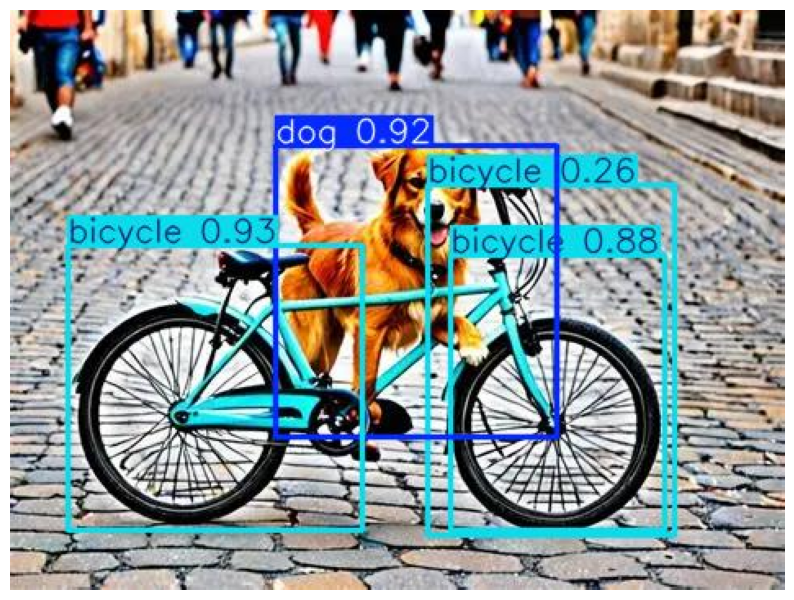

In [ ]:
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# Carregar o modelo com os pesos treinados
best_model = YOLO('/content/runs/detect/yolo_coco_project/retrained_model/weights/best.pt')

# Fazer a predição em uma imagem de teste (pode ser qualquer URL de imagem contendo cão/bicicleta)
test_image = "OIP.jpg"
results = best_model(test_image)

# Salvar e exibir o resultado
for r in results:
    im_array = r.plot() # Plota as caixas delimitadoras e rótulos
    im = Image.fromarray(im_array[..., ::-1])
    im.save('resultado.jpg')

# Exibir a imagem final no notebook
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(cv2.imread('resultado.jpg'), cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()